# EDA: checking the data before modelling
Run this notebook to see the reasoning behind the cleaning in `src/data.py` and the gait features in `src/features.py`.

The structure of this notebook is as follows:
1. Setup: loading and fixing metadata
2. Walk files (both tasks): quality checks, which walks to use, heel-strike threshold, force vs body weight
3. Task 1: class balance, confounders, features vs label
4. Task 2: choosing the severity target, features vs UPDRSM
5. Missing values (both tasks)

## 1. Setup

In [1]:
# this file uses a diagramatic approach to justify the decisions made in data.py where data is cleaned

# fixing metadata
import pandas as pd
import os
import sys
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal

sys.path.append('../src')
from data import load, parse_file_name
from data import txt_to_csv, raw_dir, out_dir
if not out_dir.exists():
    txt_to_csv(raw_dir, out_dir)

metadata_file_path = '../data/raw/others/subject_metadata.xls'
metadata_df = pd.read_excel(metadata_file_path)

#Juc010 doesnt exist in raw dataset, fixing Ju study heights (cm to m)
metadata_df = metadata_df.drop(metadata_df[(metadata_df['Study'] == 'Ju') & (metadata_df['Group'] == 'CO') & (metadata_df['Subjnum'] == 10)].index)
metadata_df.loc[metadata_df['Study'] == 'Ju', 'Height (meters)'] /= 100

# change CO/PD to Co/Pt so it matches file names
metadata_df['Group'] = metadata_df['Group'].replace({'PD': 'Pt', 'CO':'Co'})

## 2. Walk files (both tasks)
### 2.1 Quality checks

In [2]:
# checking raw data (walking files)
walking_file_path = '../data/raw'
rows = []
for file in sorted(os.listdir(walking_file_path)):
    if not file.endswith('txt'):
        continue
    walk = load(os.path.join(walking_file_path, file))
    time = walk.iloc[:, 0] #first col
    forces = walk.iloc[:, 1:] #remaining 18 col with forces
    rows.append({
        'file': file,
        **parse_file_name(file),
        'n_rows': len(walk),
        'duration_s': time.iloc[-1] - time.iloc[0],
        'has_nan': walk.isna().any().any(),
        'has_negative': (forces < 0).any().any(),
        'steady_100hz': np.allclose(np.diff(time), 0.01, atol=0.0002),
        # leading rows identical to the first row; 1 = no flat start
        'flat_start_rows': (forces != forces.iloc[0]).any(axis=1).to_numpy().argmax(),
        'mean_force': (walk['L_total'] + walk['R_total']).mean(),
    })
# ends up looking like [{'file': 'GaCo01_01.txt', 'study': 'Ga', 'group': 'Co', 'subject': 'GaCo01', 'walk': 1, 'n_rows': 12119, 'duration_s': 121.17, 'has_nan': False, 'has_negative': False, 'steady_100hz': True, 'flat_start_rows': 2, 'mean_force': 1084.0}, ...]   # 306 dicts. so rows is 1D list with dicts
quality_df = pd.DataFrame(rows)
print(quality_df)

              file study group subject  walk  n_rows  duration_s  has_nan  \
0    GaCo01_01.txt    Ga    Co  GaCo01     1   12119    121.1715    False   
1    GaCo02_01.txt    Ga    Co  GaCo02     1   12119    121.1715    False   
2    GaCo02_02.txt    Ga    Co  GaCo02     2   12119    121.1715    False   
3    GaCo03_01.txt    Ga    Co  GaCo03     1   12119    121.1715    False   
4    GaCo03_02.txt    Ga    Co  GaCo03     2   12119    121.1715    False   
..             ...   ...   ...     ...   ...     ...         ...      ...   
301  SiPt36_01.txt    Si    Pt  SiPt36     1   12119    121.1715    False   
302  SiPt37_01.txt    Si    Pt  SiPt37     1   12119    121.1715    False   
303  SiPt38_01.txt    Si    Pt  SiPt38     1   12119    121.1715    False   
304  SiPt39_01.txt    Si    Pt  SiPt39     1   12119    121.1715    False   
305  SiPt40_01.txt    Si    Pt  SiPt40     1   12119    121.1715    False   

     has_negative  steady_100hz  flat_start_rows   mean_force  
0          

file               GaCo01_01.txtGaCo02_01.txtGaCo02_02.txtGaCo03_...
study              GaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGaGa...
group              CoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCoCo...
subject            GaCo01GaCo02GaCo02GaCo03GaCo03GaCo04GaCo04GaCo...
walk                                                             844
n_rows                                                       3317550
duration_s                                                33170.1149
has_nan                                                            0
has_negative                                                       0
steady_100hz                                                     306
flat_start_rows                                                  615
mean_force                                              278813.74837
dtype: object

306

,count,mean,std,min,25%,50%,75%,max
study,,,,,,,,
Ga,113.0,120.457834,6.608274e+00,51.2364,121.1715,121.1715,121.1715,121.1715
Ju,129.0,91.499253,3.245850e+01,40.3272,78.7945,88.8438,98.3331,263.6315
Si,64.0,121.171500,1.432320e-14,121.1715,121.1715,121.1715,121.1715,121.1715


group,Co,Pt
study,,
Ga,121.1715,121.1715
Ju,85.4640,96.5032
Si,121.1715,121.1715


p = 0.034
max flat start rows: 4


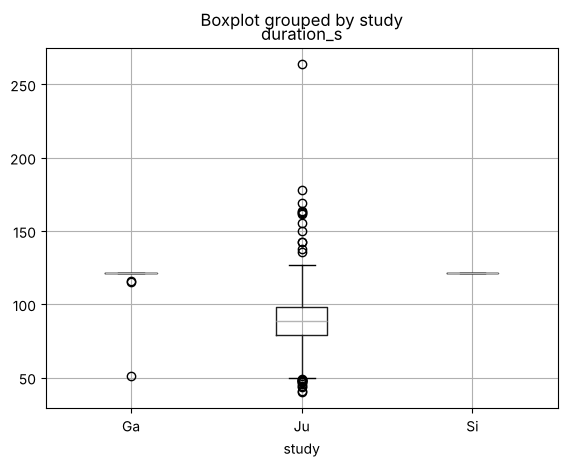

In [3]:
# has null or has_negative should be 0; steady_100hz should equal the number of walks
display(quality_df.sum())
display(len(quality_df)) # == 306
# duration by study
display(quality_df.groupby('study')['duration_s'].describe())
quality_df.boxplot(column='duration_s', by='study')

walk01 = quality_df[quality_df['walk'] == 1]
display(walk01.groupby(['study', 'group'])['duration_s'].median().unstack())
ju = walk01[walk01['study'] == 'Ju']
print(f"p = {mannwhitneyu(ju[ju['group'] == 'Co']['duration_s'], ju[ju['group'] == 'Pt']['duration_s']).pvalue:.3f}")
print('max flat start rows:', quality_df['flat_start_rows'].max())


Based on boxplot: Ga and Si walk 01 are all 121 s, but Ju walks vary (40–264 s) and Ju PD walk 01 is longer than Ju Co (median 96.5 vs 85.5 s, p = 0.034). Walk length or stride counts would therefore leak the label, so features will be computed based on stride/min instead of original totals

### 2.2 Which walks to use

In [4]:
#contingency table of study and group against walk number
table1 = pd.crosstab(index=[quality_df['study'], quality_df['group']], columns = quality_df['walk'])
print(table1)

walk         1   2   3   4   5   6   7   10
study group                                
Ga    Co     18  14   0   0   0   0   0   6
      Pt     29  25   0   0   0   0   0  21
Ju    Co     25   0   0   0   0   0   0   0
      Pt     29  13  13  13  13  12  11   0
Si    Co     29   0   0   0   0   0   0   0
      Pt     35   0   0   0   0   0   0   0


Ju walks 02–07 (cued walking) exist only for PD patients, and Ga walk 10 (dual-task) is mostly PD (21 vs 6). Including them would let the number and type of walks reveal the label. Every subject has walk 01 (usual walking), so only walk 01 is used, giving one row per subject. Same filter in list_walks() in data.py.

### 2.3 Heel-strike threshold
features.py has a feature 'heel strike' which is when the foot force rises above a threshold. This checks how the number of strikes per minute changes with that threshold.

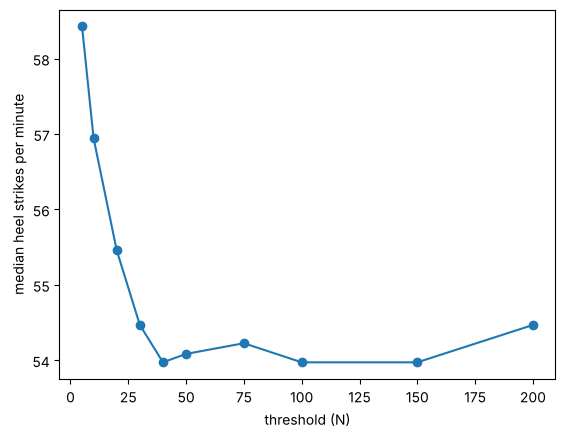

In [5]:
# deciding which threshold to pick for features.py
from data import load, list_walks, load_metadata

thresholds = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200]
walks = [load(f) for f in list_walks()['file']]
rates = []
for t in thresholds:
    per_walk = []
    for w in walks:
        on = w['L_total'].values > t
        per_walk.append((~on[:-1] & on[1:]).sum() / (w['time'].iloc[-1] / 60))
    rates.append(np.median(per_walk))
plt.plot(thresholds, rates, marker='o')
plt.xlabel('threshold (N)')
plt.ylabel('median heel strikes per minute')
plt.show()


Heel strikes per minute level off at ~54 between 40 N and 150 N, so the threshold is picked from this flat range.

### 2.4 Force vs body weight

,file,study,group,subject,walk,n_rows,duration_s,has_nan,has_negative,steady_100hz,flat_start_rows,mean_force,ID,Weight (kg)
0,GaCo01_01.txt,Ga,Co,GaCo01,1,12119,121.1715,False,False,True,2,1083.969481,GaCo01,83.0
1,GaCo02_01.txt,Ga,Co,GaCo02,1,12119,121.1715,False,False,True,2,889.185241,GaCo02,70.0
2,GaCo03_01.txt,Ga,Co,GaCo03,1,12119,121.1715,False,False,True,2,1191.904641,GaCo03,101.0
3,GaCo04_01.txt,Ga,Co,GaCo04,1,12119,121.1715,False,False,True,2,806.286703,GaCo04,65.0
4,GaCo05_01.txt,Ga,Co,GaCo05,1,12119,121.1715,False,False,True,2,1043.714464,GaCo05,88.0


r = 0.72, n = 162


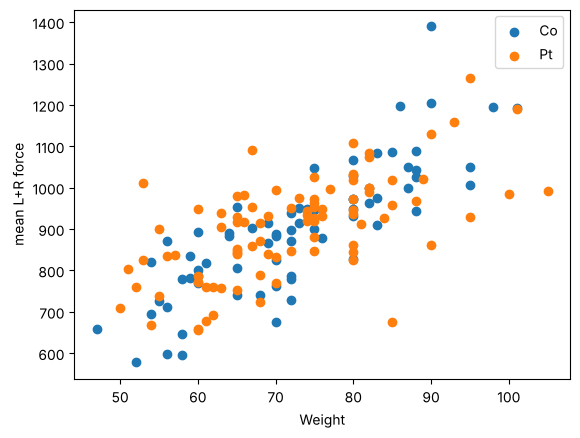

In [6]:
force_df = pd.merge(walk01, metadata_df[['ID', 'Weight (kg)']], how = 'left', left_on='subject', right_on='ID')
display(force_df.head())
for group in ['Co', 'Pt']:
    g = force_df[force_df['group'] == group]
    plt.scatter(g['Weight (kg)'], g['mean_force'], label =group)
plt.xlabel('Weight')
plt.ylabel('mean L+R force')
plt.legend()
print(f"r = {force_df['mean_force'].corr(force_df['Weight (kg)']):.2f}, n = {force_df['Weight (kg)'].notna().sum()}")


Cos obviously weight affects force, hence the check. Mean walking force rises with body weight in both groups (r = 0.72, n = 162), so force features are divided by body weight so the model learns gait and is not affected by the patients having varying weights.

## 3. Task 1: PD vs control
### 3.1 Class balance

In [7]:
table2 = pd.crosstab(index = metadata_df['Study'], columns = metadata_df['Group'], margins=True)
print(table2)

Group  Co  Pt  All
Study             
Ga     18  29   47
Ju     25  29   54
Si     29  35   64
All    72  93  165


93 PD and 72 Co, with a similar split in each study (table2). Baseline for task 1 is 93 (Pt) / 165 (All) ≈ 56%

### 3.2 Confounders

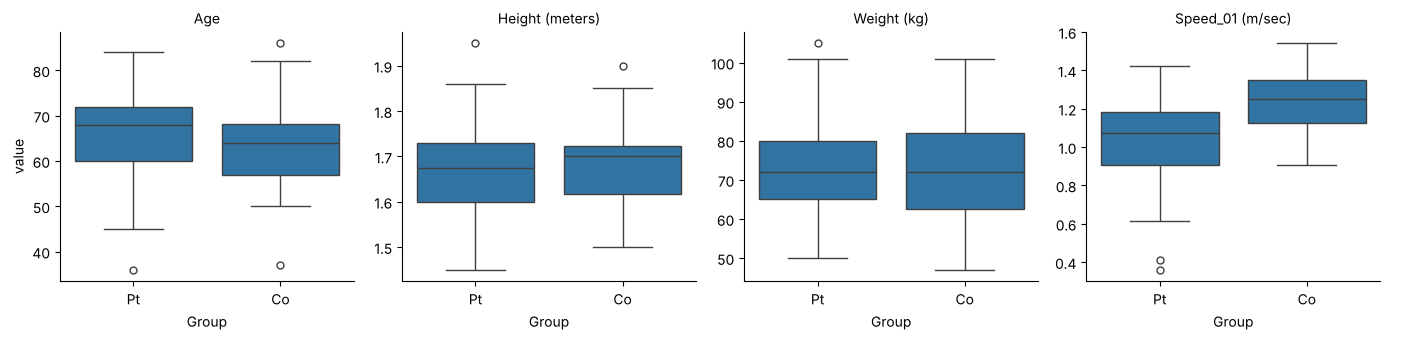

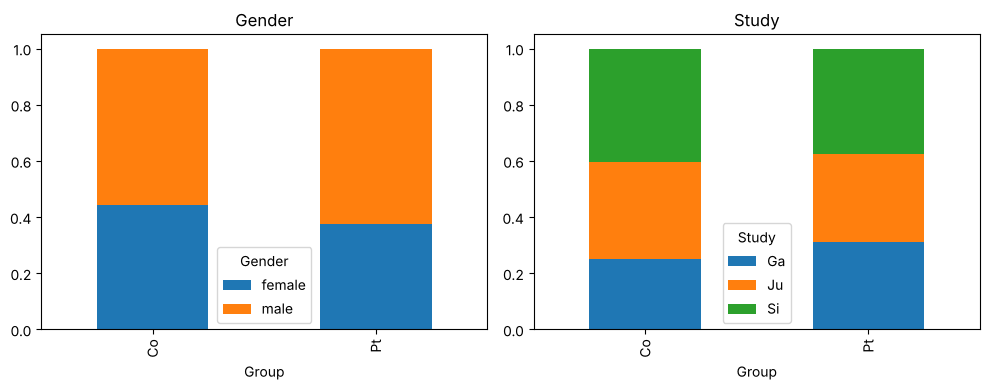

In [8]:
# finding confounders (things like height/weight may/may not affect both presence of Pd but also walks)

# visual
num_cols = ['Age', 'Height (meters)', 'Weight (kg)', 'Speed_01 (m/sec)']
long_df = metadata_df.melt(id_vars='Group', value_vars=num_cols)
g = sns.catplot(data=long_df, x='Group', y='value', col='variable',
                kind='box', sharey=False, height=3.5)
g.set_titles('{col_name}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pd.crosstab(metadata_df['Group'], metadata_df['Gender'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[0], title='Gender')
pd.crosstab(metadata_df['Group'], metadata_df['Study'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[1], title='Study')
plt.tight_layout()

In [9]:
# numerical proof
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu


chi2, p, dof, expected = chi2_contingency(pd.crosstab(metadata_df['Group'], metadata_df['Gender']))
print(f'Gender: chi2 = {chi2:.2f} \n p = {p:.3f}')

chi2, p, dof, expected = chi2_contingency(pd.crosstab(metadata_df['Group'], metadata_df['Study']))
print(f'Study: chi2 = {chi2:.2f} \n p = {p:.3f}')

pt = metadata_df[metadata_df['Group'] == 'Pt']
co = metadata_df[metadata_df['Group'] == 'Co']
res = mannwhitneyu(pt[num_cols], co[num_cols], nan_policy='omit')

print(metadata_df.groupby('Group')[num_cols].median())
print(pd.Series(res.pvalue, index=num_cols).round(3))
print(metadata_df.groupby(['Study', 'Group'])['Age'].median().unstack())


Gender: chi2 = 0.52 
 p = 0.469
Study: chi2 = 0.77 
 p = 0.679
        Age  Height (meters)  Weight (kg)  Speed_01 (m/sec)
Group                                                      
Co     64.0            1.700         72.0            1.2485
Pt     68.0            1.675         72.0            1.0750
Age                 0.040
Height (meters)     0.528
Weight (kg)         0.843
Speed_01 (m/sec)    0.000
dtype: float64
Group    Co    Pt
Study            
Ga     69.0  71.0
Ju     65.0  68.0
Si     57.0  63.0


Since both categorical data have p > 0.05 both Groups have similar gender/study split. Height and weight do not differ (p > 0.5). PD are older (median 68 vs 64, p = 0.040) in every study, so age is a confounder; Task 1 uses gait only, so this is reported as a limitation. For speed, p < 0.001 which means Pd walk slower which is expected as it is a symptom.

All other variables kept ~consistent. Like study, gender, height, weight, walk. Only thing varied is whether Co/Pt. 

### 3.3 Features vs label
Each of the 5 features from features.py plotted against the Task 1 label. Boxplots are used because the label is a category (Co or Pt), so the spread of each feature can be compared side by side between the two groups. Mann-Whitney p-values check whether the difference is real.

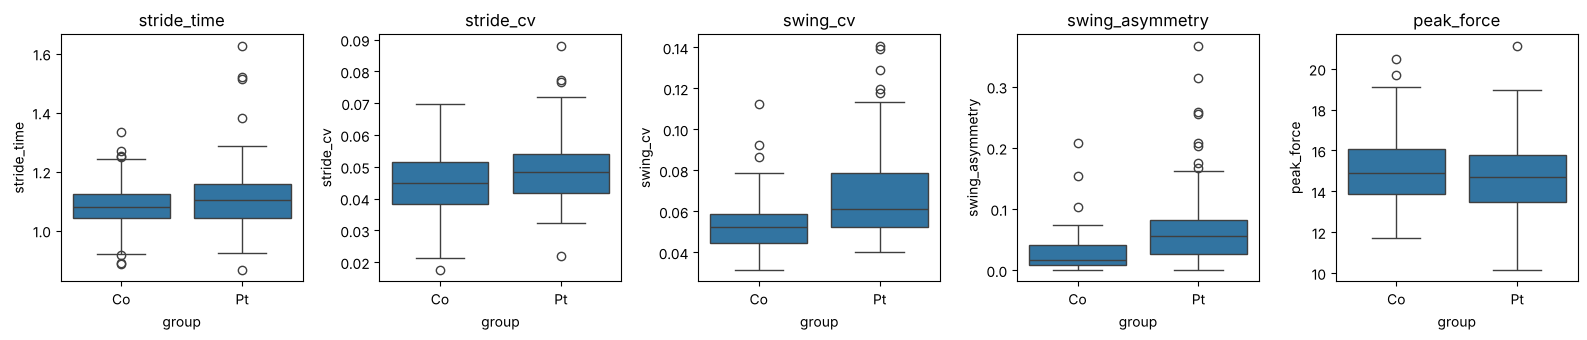

stride_time        0.184
stride_cv          0.030
swing_cv           0.000
swing_asymmetry    0.000
peak_force         0.437
dtype: float64


In [10]:
sys.path.append('..')
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
from features import X, y

feat = X.assign(group=y.map({0: 'Co', 1: 'Pt'}))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, X.columns):
    sns.boxplot(data=feat, x='group', y=col, order=['Co', 'Pt'], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(pd.Series({col: mannwhitneyu(X[col][y == 0], X[col][y == 1]).pvalue for col in X.columns}).round(3))


swing_cv and swing_asymmetry are clearly higher in PD (p < 0.001) and stride_cv slightly higher (p = 0.030). stride_time (p = 0.184) and peak_force (p = 0.437) barely differ between groups, so they are the weakest features for Task 1.

## 4. Task 2: severity (PD only)

### 4.1 Severity target

       count       mean   min   max
Study                              
Ga      29.0  17.896552   5.0  36.0
Ju      29.0  15.793103   8.0  25.0
Si      33.0  23.666667  12.0  44.0
UPDRSM by study: p = 0.0001
HoehnYahr
2.0    55
2.5    28
3.0    10
Name: count, dtype: int64


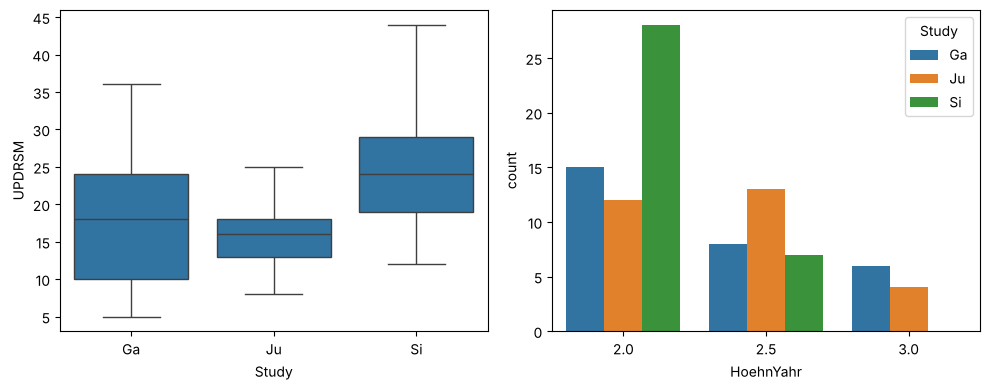

In [11]:
pd_df = metadata_df[metadata_df['Group'] == 'Pt']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=pd_df, x='Study', y='UPDRSM', ax=axes[0])
sns.countplot(data=pd_df, x='HoehnYahr', hue='Study', ax=axes[1])
plt.tight_layout()

print(pd_df.groupby('Study')['UPDRSM'].describe()[['count', 'mean', 'min', 'max']])
print(f"UPDRSM by study: p = {kruskal(*[g['UPDRSM'].dropna() for _, g in pd_df.groupby('Study')]).pvalue:.4f}")
print(pd_df['HoehnYahr'].value_counts().sort_index())


In [12]:
#close to -1/1 strong corr with UPDRSM (most commonly used metric in Parkinsons Gait)
sev_cols = ['HoehnYahr', 'Age', 'Speed_01 (m/sec)', 'TUAG']
print(pd_df[['UPDRSM', 'UPDRS'] + sev_cols].corr(method='spearman')['UPDRSM'])


UPDRSM              1.000000
UPDRS               0.886392
HoehnYahr          -0.007813
Age                -0.185832
Speed_01 (m/sec)   -0.039558
TUAG                0.230761
Name: UPDRSM, dtype: float64


UPDRSM differs by study (p = 0.0001), so study can affect Task 2 results. Hoehn & Yahr only takes 3 values (2, 2.5, 3) and barely correlates with UPDRSM (ρ = −0.01), so UPDRSM is the Task 2 target. UPDRS is not used as a predictor since it includes UPDRSM.

### 4.2 Features vs UPDRSM
The same 5 features plotted against UPDRSM for the PD patients with a UPDRSM score. Scatter plots are used because UPDRSM is a number, not a category, so the question is whether a feature rises or falls as UPDRSM rises. The line shows the trend and Spearman ρ measures it (−1 to 1, 0 = no relation).

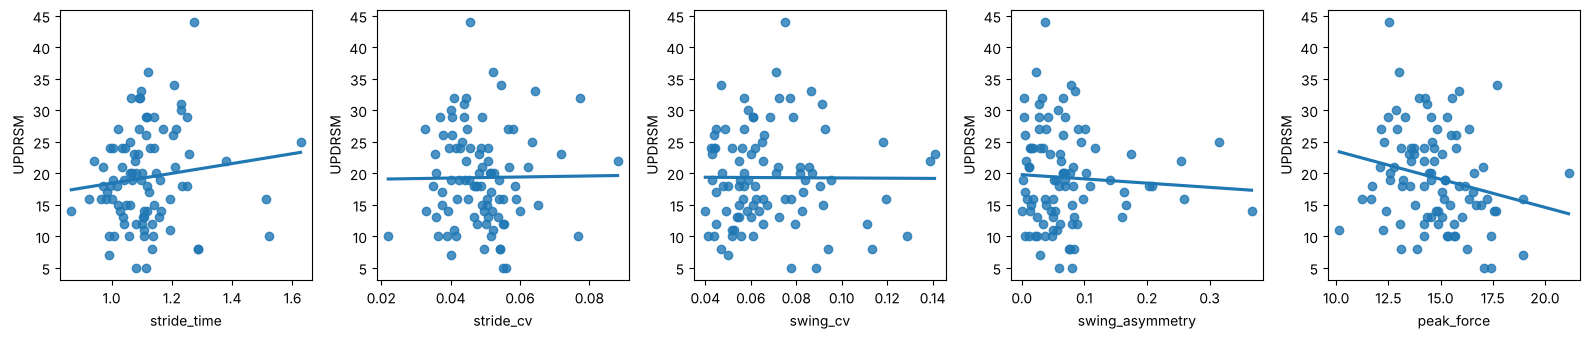

91 patients
stride_time        0.14
stride_cv         -0.07
swing_cv           0.04
swing_asymmetry   -0.05
peak_force        -0.24
UPDRSM             1.00
Name: UPDRSM, dtype: float64


In [13]:
sev = X.join(pd_df.set_index('ID')['UPDRSM'], how='inner').dropna()
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, X.columns):
    sns.regplot(data=sev, x=col, y='UPDRSM', ci=None, ax=ax)
plt.tight_layout()
plt.show()

print(len(sev), 'patients')
print(sev.corr(method='spearman')['UPDRSM'].round(2))

The points form a cloud with nearly flat lines, and every ρ is close to 0 apart from peak_force (ρ = −0.24). The gait features barely track UPDRSM, so UPDRSM will be hard to predict from gait alone.

## 5. Missing values (both tasks)

In [14]:
# Nan for each col, groupby group
with_missing = metadata_df.drop(columns=['ID', 'Study', 'Group', 'Subjnum', 'Gender', 'Age']).isna().groupby(metadata_df['Group']).sum().T
print(with_missing)

gap_cols = ['Height (meters)', 'Weight (kg)', 'TUAG', 'Speed_01 (m/sec)', 'UPDRSM']
print(pt[pt[gap_cols].isna().any(axis=1)][['ID'] + gap_cols])
print(co[co['Weight (kg)'].isna()][['ID', 'Weight (kg)']])


Group             Co  Pt
Height (meters)    0   3
Weight (kg)        1   2
HoehnYahr         54   0
UPDRS             29   2
UPDRSM            29   2
TUAG              10   3
Speed_01 (m/sec)   0   1
Speed_10          67  78
        ID  Height (meters)  Weight (kg)   TUAG  Speed_01 (m/sec)  UPDRSM
0   GaPt03             1.45         50.0  36.34               NaN    10.0
1   GaPt04             1.71          NaN  11.00             0.642     8.0
9   GaPt14             1.95        105.0    NaN             1.369    19.0
10  GaPt15              NaN         80.0  10.32             0.948    20.0
14  GaPt19              NaN         55.0  13.20             1.124    22.0
16  GaPt21              NaN         63.0  14.06             1.166    27.0
17  GaPt22             1.78         65.0    NaN             0.802    29.0
18  GaPt23             1.60          NaN  25.01             0.360    25.0
58  SiPt02             1.58         67.0    NaN             0.770     NaN
61  SiPt07             1.66        

Dealing with missing data: controls have no H&Y/UPDRS (not applicable), and Speed_10 only exists for Ga dual-task walks, which are not used. SiPt02 and SiPt07 have no UPDRSM, so they are left out of Task 2 but stay in Task 1; the target is never imputed. Weight is needed to divide force, so the 3 missing weights (GaPt04, GaPt23, SiCo17) as well as missing height, tuag, speed all filled with median in data.py